* Bibliotecas e funções, não apagar a célula escondida abaixo!

In [46]:
# INICIALIZAÇÃO DAS BIBLIOTECAS
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
#%matplotlib inline

#INICIALIZAÇÃO DAS FUNÇÕES
def set_rho(ff, rho_fat = np.array(0.05)):
    '''
    This function calculates fat and water proton densities (rho_fat and rho_water), given a fat fraction value (ff).
    rho_fat is by default fixed as = 0.05, and can be optionally be passed as an argument.
    rho_water is calculated as a function of ff and rho_fat.
    Parameters: ff -> float 0>1
                rho_fat (optional) -> float >0
    Returns:    rho_fat -> float >0 
                rho_water -> float >0
    '''
    #rho_fat = np.array(0.05)
    rho_water = np.array((rho_fat*((1-ff)/ff)))
    return (rho_fat,rho_water)

def discrete_timeseries(n_echoes):
    '''
    This function calculates the GRE IP-OP signal echo times for fat-water studies at 3T, given the number of echoes.
    Parameters: n_echoes     -> integer >0, number of equally spaced echoes (standard values range from 2 to 7)
    Returns:    echo_times -> float >0, time in seconds (equivalent to xdata)
     '''
    
    #TE acquisition times for n echoes
    echo_times = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True)
    
    return echo_times

def gen_GRE_t2(echo_times, rho_fat, rho_water, t2star=[0.030,0.040,0.051,0.052,0.062,0.083,0.023]):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T.
    It is based on studies by Hamilton.
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
                t2star     -> array >0, T2* values for fat peaks at 5.3, 4.2, 2.75, 2.1, 1.3 and 0.9 ppm (fat) and water 
                returns:    Sabs -> float > 0, absolute signal intensity in arbitrary units (equivalent to ydata)
    '''
    rho = np.array([rho_fat*0.047,\
    rho_fat*0.039,\
    rho_fat*0.006,\
    rho_fat*0.12,\
    rho_fat*0.7,\
    rho_fat*0.088,\
    rho_water]) #rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    
    #standard, individual T2* values
    '''
    t2star = np.array([0.030,\
              0.040,\
              0.051,\
              0.052,\
              0.062,\
              0.083,\
              0.023] )
    '''
    #frequency in parts per million for each moiety
    freq_ppm = np.array([5.3,\
             4.2,\
             2.75,\
             2.1,\
             1.3,\
             0.9,\
             4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0) #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.577e6) #Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    #calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    #obtain sum & absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    Sabs = np.sum(S, axis=0)
    Sabs = np.absolute(np.sum(S, axis=0))
    return (Sabs)

def gen_GRE_t2_noise(echo_times, rho_fat, rho_water, t2star=[0.030,0.040,0.051,0.052,0.062,0.083,0.023], noise_sd=0.01):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T.
    It is based on studies by Hamilton (T2* and characteristic ppm frequency values).
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
                t2star     -> array >0, T2* values for fat peaks at 5.3, 4.2, 2.75, 2.1, 1.3 and 0.9 ppm (fat) and water
                noise_sd   -> float >0, noise standard deviation as proportion of the first signal point intensity (default is 1% = 0.01)
    returns:    Sabs -> float > 0, absolute signal intensity in arbitrary units (equivalent to ydata)
    '''
    rho = np.array([rho_fat*0.047,\
    rho_fat*0.039,\
    rho_fat*0.006,\
    rho_fat*0.12,\
    rho_fat*0.7,\
    rho_fat*0.088,\
    rho_water]) #rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    
    #standard, individual T2* values
    '''
    t2star = np.array([0.030,\
              0.040,\
              0.051,\
              0.052,\
              0.062,\
              0.083,\
              0.023] )
    '''
    #frequency in parts per million for each moiety
    freq_ppm = np.array([5.3,\
             4.2,\
             2.75,\
             2.1,\
             1.3,\
             0.9,\
             4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0) #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.577e6) #Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    #calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    #obtain sum & add noise
    Ssum= (len(echo_times))
    Ssum=np.zeros(Ssum,dtype='complex')
    Ssum = np.sum(S, axis=0)
    
    for t,TE in enumerate(echo_times):
        Ssum[t] = Ssum[t].real+Ssum[0].real*np.random.normal(scale=noise_sd)+1j*(Ssum[t].imag+Ssum[0].imag*np.random.normal(scale=noise_sd))

    
    #obtain absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    Sabs = np.absolute(Ssum)
    return (Sabs)

def continuous_timeseries(endpoint=0.01):
    '''
    This function returns a timeseries consisting of 1000 points, by default ranging from t=0 to t=0.01.
    It is useful for plotting the fitted curve.
    Parameters: endpoint (optional) -> float >0, time in seconds to end the series
    Returns:    array -> float >0, time in seconds (equivalent to xdata)
    '''
    return np.linspace(0, endpoint, 1000, endpoint=True)   

def calc_fatfrac(fitted_parameters):
    '''
    This function calculates the fat fraction based on the fitted parameters for rho_fat and rho_water, where:
    rho_fat = fitted_parameters[0]
    rho_water = fitted_parameters[1]
    Parameters: fitted_parameters -> float (array), proton density for fat and water
    Returns:    scalar -> float >0, fat fraction
    '''
    return  fitted_parameters[0] / (fitted_parameters[0] + fitted_parameters[1])

def fit_multiinterf(echo_times, rho_fat, rho_water, t2star):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T.
    It is based on studies by Hamilton (T2* and characteristic ppm frequency values).
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
    returns:    Sabs -> float > 0, absolute signal intensity in arbitrary units (equivalent to ydata)
    '''
    
    echo_times = np.array(echo_times)
    rho_fat = np.array(rho_fat)
    rho_water = np.array(rho_water)
    t2star = np.array(t2star)
    
    #cn is the fractional proton density of each fat moiety (Yokoo) (see freq_ppm)
    cn = np.array([0.12, 0.7, 0.088,]) 
    
    #frequency in parts per million for each fat moiety
    ppm_fat = np.array([2.1, 1.3, 0.9])
    ppm_water = np.array(4.7)
    
    magField = np.array(3.0) #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.577e6) #Hydrogen gyromagnetic ratio, Hz/T
    freq_water = np.array(ppm_water*magField*hydroGyro/1e6) #water frequency in Hertz
    
    #relative frequency for each fat to that of water
    freqr_fat = np.zeros(len(ppm_fat))
    for n, fppm in enumerate(ppm_fat):
        freqr_fat[n] = freq_water-(fppm*magField*hydroGyro/1e6)
    
    #calculate the signal for each moiety    
    S = (len(freqr_fat),len(echo_times))
    S = np.zeros(S,dtype='complex')
        #three fat signals
    for n, moieties in enumerate(freqr_fat):
        for t,TE in enumerate(echo_times):
            S[n,t] = cn[n]*np.exp(2.0*np.pi*1j*freqr_fat[n]*TE)
    
    Ssum= len(echo_times)
    Ssum = np.zeros(Ssum)
    Ssum = np.sum(S, axis=0) #sum of fat signals
    Sabs = np.absolute(rho_water + rho_fat*Ssum) #multiply rho_fat and add rho_water, take absolute value
    Sfinal = len(echo_times)
    Sfinal = np.zeros(Sfinal)
    for t,TE in enumerate(echo_times):
        Sfinal[t] = Sabs[t]*np.exp(-TE/t2star) #exponential decay
    
    return (Sfinal)

def dixon(voxelSignal):
    '''
    this function calculates the fat fraction according to Dixon's method.
    parameters: voxelSignal -> array, float >0, signal intensities, at least two values.
    returns:    fat_fraction -> float
    '''
    s1 = voxelSignal[0]
    s2 = voxelSignal[1]
    
    rho_water = (s2 + s1)/2
    rho_fat = (s2 - s1)/2
    
    return(rho_fat, rho_water)

def tripleEcho(echo_times, voxelSignal):
    '''
    this function calculates the fat fraction according to corrected Dixon's method, which considers a single T2* effect.
    parameters: voxelSignal -> array, float >0, signal intensities, at least two values.
    returns:    fat_fraction -> float
    '''
    s1 = voxelSignal[0]
    s2 = voxelSignal[1]
    s4 = voxelSignal[3]
    deltaTE = echo_times[1]-echo_times[0]
    t2star = deltaTE/np.log(s2/s4)
    
    rho_water = (s2 * np.exp(-echo_times[1]/t2star) + s1* np.exp(-echo_times[0]/t2star))/2
    rho_fat = (s2 * np.exp(-echo_times[1]/t2star) - s1* np.exp(-echo_times[0]/t2star))/2

    return(rho_fat, rho_water)

### Sinal de referência: ###
Sinal GRE para referência simulado com e sem ruído. Os pontos marcam os TEs utilizados nas imagens em 3 Tesla. Somente eles serão utilizados para a quantificação, mas a visão da curva permite perceber a presença do ruído e sua forma característica. Os valores de T2\* são os padrões encontrados por Hamilton, diferentes para cada molécula de gordura e para a água. Para o gráfico abaixo, foi utilizada fração de gordura de 10%. O ruído é de 2% do valor do sinal no primeiro eco, valor aproximado do encontrado nas imagens dos pacientes subj01 e subj02 (estudo de 2016, 3T) em relação à região de interesse extraída do fígado. 

0.1


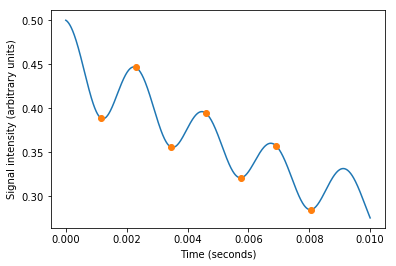

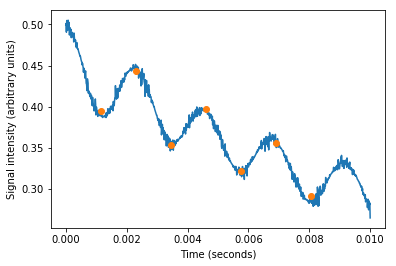

In [60]:
rf, rw = set_rho(0.1) #rf = rho fat, rw = rho water
ff_calc = calc_fatfrac([rf, rw])
print ff_calc

#sinal limpo
xdata = discrete_timeseries(7)
ydata = gen_GRE_t2(xdata, rf, rw) #usa gen_GRE para gerar os pontos
xcont = continuous_timeseries()
ycont = gen_GRE_t2(xcont, rf, rw)

plt.plot(xcont,ycont,'-')
plt.plot(xdata,ydata,'o')
plt.xlabel('Time (seconds)')
plt.ylabel('Signal intensity (arbitrary units)')
plt.show()

#sinal com ruido
ydata_noise = gen_GRE_t2_noise(xdata, rf, rw) #usa gen_GRE para gerar os pontos
ycont_noise = gen_GRE_t2_noise(xcont, rf, rw)

plt.plot(xcont_noise,ycont_noise,'-')
plt.plot(xdata_noise,ydata_noise,'o')
plt.xlabel('Time (seconds)')
plt.ylabel('Signal intensity (arbitrary units)')
plt.show()

### Dixon sem ruído

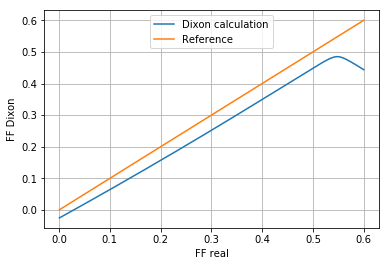

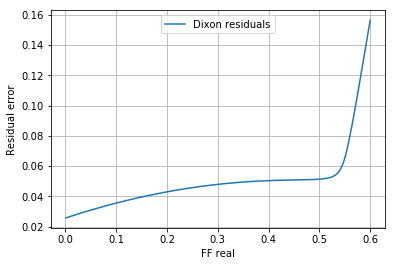

In [17]:
FF = np.linspace(0.001, 0.6, 200)
FFmulti = (len(FF))
FFmulti=np.zeros(FFmulti)
FFreal = (len(FF))
FFreal=np.zeros(FFreal)

for iteration,fatPercent in enumerate(FF):
    rf, rw = set_rho(fatPercent)

    xdata = discrete_timeseries(7)
    ydata = gen_GRE_t2(xdata, rf, rw)

    fitted_param = dixon(ydata)

    ff_calc = calc_fatfrac(fitted_param)
    
    FFmulti[iteration] = ff_calc
    FFreal[iteration] = fatPercent

#plot
fig, ax = plt.subplots()    
ax.plot(FFreal,FFmulti,'-', label="Dixon calculation")
ax.plot(FFreal,FFreal,'-', label="Reference")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('FF Dixon')
plt.grid()
plt.show()

#plot residuals
multi_residuals = FFreal-FFmulti
fig, ax = plt.subplots()    
ax.plot(FFreal, multi_residuals,'-', label="Dixon residuals")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('Residual error')
plt.grid()
plt.show()

### Dixon com ruído

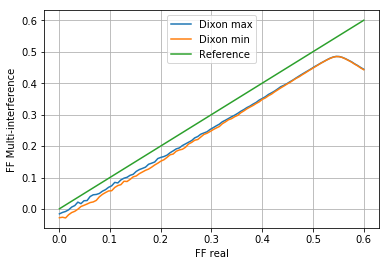

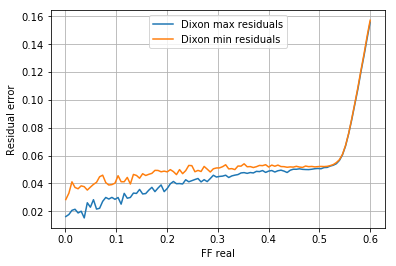

In [57]:
FF = np.linspace(0.001, 0.6, 100)
FFmulti = (len(FF))
FFmulti=np.zeros(FFmulti)
FFreal = (len(FF))
FFreal=np.zeros(FFreal)

noise_level = 0.02
noise_counts = 10
FFmulti_list = np.zeros((noise_counts, len(FF)))
FFmulti_max = np.zeros(len(FF))
FFmulti_min = np.zeros(len(FF))

for n_count in range(0, noise_counts):
    for iteration,fatPercent in enumerate(FF):
        rf, rw = set_rho(fatPercent)

        xdata = discrete_timeseries(7)
        ydata = gen_GRE_t2_noise(xdata, rf, rw)

        fitted_param = dixon(ydata)

        ff_calc = calc_fatfrac(fitted_param)

        FFmulti[iteration] = ff_calc
        FFreal[iteration] = fatPercent

    FFmulti_list[n_count,:] = FFmulti

FFmulti_max = np.amax(FFmulti_list, axis=0)
FFmulti_min = np.amin(FFmulti_list, axis=0)
      
        
        
#plot
fig, ax = plt.subplots()    
ax.plot(FFreal,FFmulti_max,'-', label="Dixon max")
ax.plot(FFreal,FFmulti_min,'-', label="Dixon min")
ax.plot(FFreal,FFreal,'-', label="Reference")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('FF Multi-interference')
plt.grid()
plt.show()



#plot residuals
max_residuals = FFreal-FFmulti_max
min_residuals = FFreal-FFmulti_min
fig, ax = plt.subplots()    
ax.plot(FFreal, max_residuals,'-', label="Dixon max residuals")
ax.plot(FFreal, min_residuals,'-', label="Dixon min residuals")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('Residual error')
plt.grid()
plt.show()

### Triplo eco sem ruído

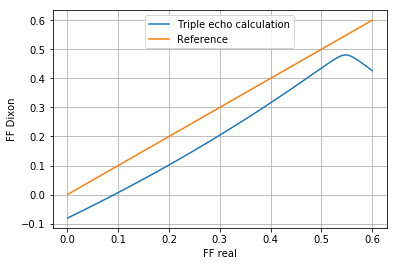

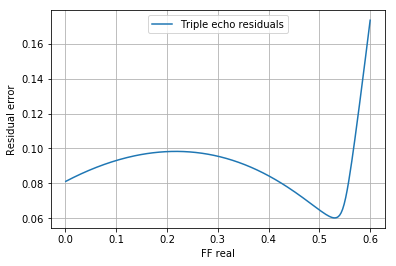

In [48]:
FF = np.linspace(0.001, 0.6, 200)
FFmulti = (len(FF))
FFmulti=np.zeros(FFmulti)
FFreal = (len(FF))
FFreal=np.zeros(FFreal)

for iteration,fatPercent in enumerate(FF):
    rf, rw = set_rho(fatPercent)

    xdata = discrete_timeseries(7)
    ydata = gen_GRE_t2(xdata, rf, rw)

    fitted_param = tripleEcho(xdata, ydata)
    ff_calc = calc_fatfrac(fitted_param)
    
    FFmulti[iteration] = ff_calc
    FFreal[iteration] = fatPercent

#plot
fig, ax = plt.subplots()    
ax.plot(FFreal,FFmulti,'-', label="Triple echo calculation")
ax.plot(FFreal,FFreal,'-', label="Reference")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('FF Dixon')
plt.grid()
plt.show()

#plot residuals
multi_residuals = FFreal-FFmulti
fig, ax = plt.subplots()    
ax.plot(FFreal, multi_residuals,'-', label="Triple echo residuals")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('Residual error')
plt.grid()
plt.show()

### Triplo eco com ruído

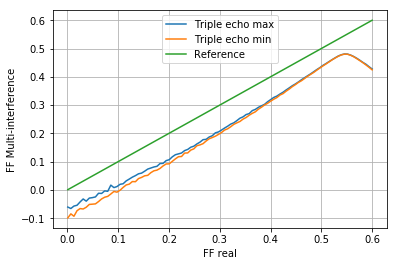

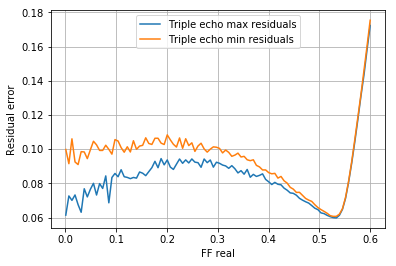

In [58]:
FF = np.linspace(0.001, 0.6, 100)
FFmulti = (len(FF))
FFmulti=np.zeros(FFmulti)
FFreal = (len(FF))
FFreal=np.zeros(FFreal)

noise_level = 0.02
noise_counts = 10
FFmulti_list = np.zeros((noise_counts, len(FF)))
FFmulti_max = np.zeros(len(FF))
FFmulti_min = np.zeros(len(FF))

for n_count in range(0, noise_counts):
    for iteration,fatPercent in enumerate(FF):
        rf, rw = set_rho(fatPercent)

        xdata = discrete_timeseries(7)
        ydata = gen_GRE_t2_noise(xdata, rf, rw)

        fitted_param = tripleEcho(xdata, ydata)
        ff_calc = calc_fatfrac(fitted_param)

        FFmulti[iteration] = ff_calc
        FFreal[iteration] = fatPercent

    FFmulti_list[n_count,:] = FFmulti

FFmulti_max = np.amax(FFmulti_list, axis=0)
FFmulti_min = np.amin(FFmulti_list, axis=0)
      
        
        
#plot
fig, ax = plt.subplots()    
ax.plot(FFreal,FFmulti_max,'-', label="Triple echo max")
ax.plot(FFreal,FFmulti_min,'-', label="Triple echo min")
ax.plot(FFreal,FFreal,'-', label="Reference")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('FF Multi-interference')
plt.grid()
plt.show()



#plot residuals
max_residuals = FFreal-FFmulti_max
min_residuals = FFreal-FFmulti_min
fig, ax = plt.subplots()    
ax.plot(FFreal, max_residuals,'-', label="Triple echo max residuals")
ax.plot(FFreal, min_residuals,'-', label="Triple echo min residuals")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('Residual error')
plt.grid()
plt.show()

### Multi-interferência sem ruído

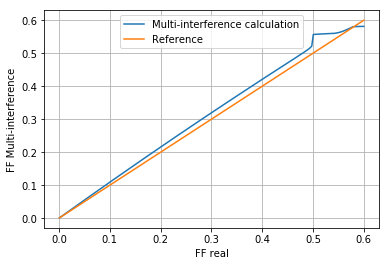

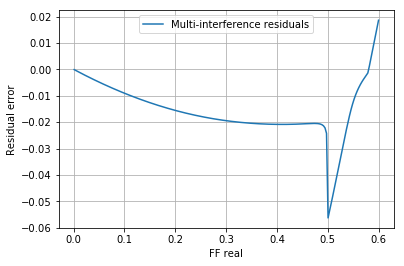

In [54]:
FF = np.linspace(0.001, 0.6, 200)
FFmulti = (len(FF))
FFmulti=np.zeros(FFmulti)
FFreal = (len(FF))
FFreal=np.zeros(FFreal)

for iteration,fatPercent in enumerate(FF):
    rf, rw = set_rho(fatPercent)

    xdata = discrete_timeseries(7)
    ydata = gen_GRE_t2(xdata, rf, rw)

    bd = (0, [np.inf, np.inf, 1])
    fitted_param, pcv = curve_fit(fit_multiinterf, xdata, ydata, bounds=bd)

    x_cont = continuous_timeseries()
    y_fit = fit_multiinterf(x_cont, *fitted_param)

    ff_calc = calc_fatfrac(fitted_param)
    
    FFmulti[iteration] = ff_calc
    FFreal[iteration] = fatPercent

#plot
fig, ax = plt.subplots()    
ax.plot(FFreal,FFmulti,'-', label="Multi-interference calculation")
ax.plot(FFreal,FFreal,'-', label="Reference")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('FF Multi-interference')
plt.grid()
plt.show()

#plot residuals
multi_residuals = FFreal-FFmulti
fig, ax = plt.subplots()    
ax.plot(FFreal, multi_residuals,'-', label="Multi-interference residuals")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('Residual error')
plt.grid()
plt.show()

### Multi-interferência com ruído

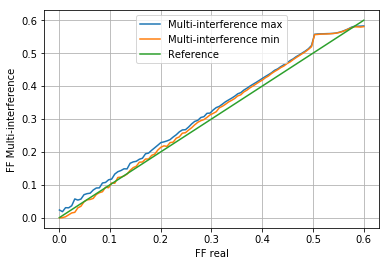

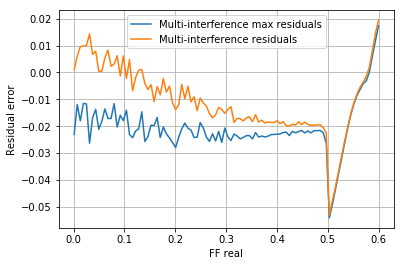

In [59]:
FF = np.linspace(0.001, 0.6, 100)
FFmulti = (len(FF))
FFmulti=np.zeros(FFmulti)
FFreal = (len(FF))
FFreal=np.zeros(FFreal)

noise_level = 0.02
noise_counts = 10
FFmulti_list = np.zeros((noise_counts, len(FF)))
FFmulti_max = np.zeros(len(FF))
FFmulti_min = np.zeros(len(FF))

for n_count in range(0, noise_counts):
    for iteration,fatPercent in enumerate(FF):
        rf, rw = set_rho(fatPercent)

        xdata = discrete_timeseries(7)
        ydata = gen_GRE_t2_noise(xdata, rf, rw, noise_sd=noise_level)

        bd = (0, [np.inf, np.inf, 1])
        fitted_param, pcv = curve_fit(fit_multiinterf, xdata, ydata, bounds=bd)

        x_cont = continuous_timeseries()
        y_fit = fit_multiinterf(x_cont, *fitted_param)

        ff_calc = calc_fatfrac(fitted_param)

        FFmulti[iteration] = ff_calc
        FFreal[iteration] = fatPercent

    FFmulti_list[n_count,:] = FFmulti

FFmulti_max = np.amax(FFmulti_list, axis=0)
FFmulti_min = np.amin(FFmulti_list, axis=0)
      
      
#plot
fig, ax = plt.subplots()    
ax.plot(FFreal,FFmulti_max,'-', label="Multi-interference max")
ax.plot(FFreal,FFmulti_min,'-', label="Multi-interference min")
ax.plot(FFreal,FFreal,'-', label="Reference")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('FF Multi-interference')
plt.grid()
plt.show()



#plot residuals
max_residuals = FFreal-FFmulti_max
min_residuals = FFreal-FFmulti_min
fig, ax = plt.subplots()    
ax.plot(FFreal, max_residuals,'-', label="Multi-interference max residuals")
ax.plot(FFreal, min_residuals,'-', label="Multi-interference residuals")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('Residual error')
plt.grid()
plt.show()